## **Trabajo Práctico 2 - Reconstrucción 3D**

In [1]:
import os
import pickle
import cv2
import numpy as np
import utils

CARPETA_CALIB = "../data/calib"
CARPETA_CAPTURAS = "../data/captures"

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Apertura de los csv de datos y cálculo de la línea baseline entre los centros de ambas cámaras
</p>

In [2]:
with open("../data/stereo_calibration.pkl", "rb") as f:
    calib_pkl = pickle.load(f)
with open("../data/stereo_maps.pkl", "rb") as f:
    mapas_pkl = pickle.load(f)

print("Baseline:", np.linalg.norm(calib_pkl["T"]).round(4), "mm")

Baseline: 59.8382 mm


### Estimación del tamaño del cuadrado
OpenCV necesita el tamaño real del cuadrado del tablero para que la calibración quede en milímetros. Como no lo conocíamos, calibramos primero con un cuadrado de **1** (sin unidades): así el baseline queda expresado en "cuadrados". Comparándolo con el baseline de la calibración de `calib-stereo` (59.838 mm), despejamos el lado del cuadrado en mm.


In [3]:
# Calibramos con cuadrado = 1: el baseline queda medido en "cuadrados"
obj_puntos_1, pts_izq_1, pts_der_1, img_size = utils.detectar_esquinas(CARPETA_CALIB, (9, 6), 1.0)
calib_unitaria = utils.calibracion_estereo(obj_puntos_1, pts_izq_1, pts_der_1, img_size)

baseline_cuadrados = np.linalg.norm(calib_unitaria["T"])   
baseline_mm = np.linalg.norm(calib_pkl["T"])             

print("Baseline en mm:", baseline_mm.round(4))

Descartamos ../data/calib/left_3.jpg porque no se detecto el tablero en ambas imagenes
39 pares válidos
Baseline en mm: 59.8382


In [4]:
# Si 2.137 cuadrados = 59.8382 mm, entonces 1 cuadrado = 59.8382 / 2.137 mm
size_cuadrado_mm = baseline_mm / baseline_cuadrados
print(f"Tamaño del cuadrado: {size_cuadrado_mm:.2f} mm")  

Tamaño del cuadrado: 28.02 mm


<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Como se busca calcular la profundidad de cada pixel de la imagen izquierda, necesitamos encontrar el mismo punto en la derecha. Sabemos que ese punto, siguiendo la geometria epipolar, cae sobre la linea epipolar que, originalmente se encuentra inclinada y por la distorsion, curva, por lo que la busqueda es costosa. 
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Para ello, resulta util la rectificacion, con la cual se logra "girar" las camaras de forma que los planos imagen queden paralelos y las lineas epipolares horizontales y a la misma altura en ambas imagenes. Con esto, los puntos de la imagen izquierda se hallan a la misma altura en la derecha (en la misma fila), pero trasladados horizontalmente. Esto ultimo es la disparidad. 
</p>

In [5]:
objetos_puntos, pts_izq, pts_der, img_size = utils.detectar_esquinas(CARPETA_CALIB, (9, 6), size_cuadrado_mm)
calib = utils.calibracion_estereo(objetos_puntos, pts_izq, pts_der, img_size, True)
rect = utils.rectificacion(calib_unitaria)

Descartamos ../data/calib/left_3.jpg porque no se detecto el tablero en ambas imagenes
39 pares válidos
Error RMS camara izquierda: 0.604 pixeles
Error RMS camara derecha: 0.949 pixeles
Error RMS estéreo: 0.799 pixeles
Baseline en cuadrados: 59.838 mm


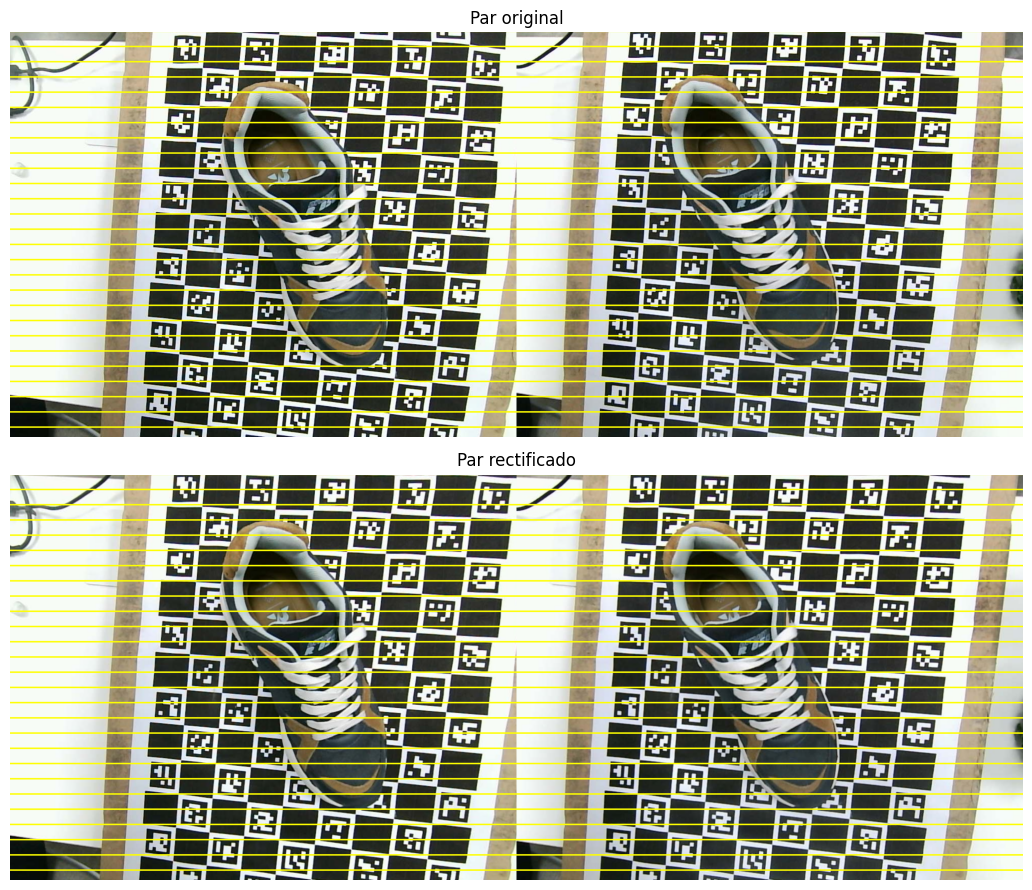

In [11]:
# Verificamos la rectificacion
img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, "left_0.jpg"))
img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, "right_0.jpg"))
utils.graficar_rectificacion(img_izq, img_der, rect, recorte = (50, 850, 550, 1550), paso = 30, grosor = 2) 